# 03 — Network Accessibility

Builds (or loads cached) OSMnx walk network for Snohomish County, then
computes gravity-model accessibility scores at block group centroids.

**Note:** OSM download takes 5–10 min. Run once; it caches to `data/raw/osm/`.
Similarly, pandana precompute is cached to HDF5 after first run.

**Outputs:**
- `data/raw/osm/snohomish_walk.graphml`
- `data/processed/pandana_network.h5`
- `data/processed/accessibility_scores.parquet`

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path('..').resolve()))

import geopandas as gpd
import pandas as pd

from transit_gaps.network import build_network, save_network, load_network, get_route_lines
from transit_gaps.accessibility import compute_accessibility

In [2]:
PANDANA_CACHE = Path('../data/processed/pandana_network.h5')

if PANDANA_CACHE.exists():
    from transit_gaps.network import load_network
    network = load_network(PANDANA_CACHE)
    # Still need nodes/edges for route overlay
    import osmnx as ox
    from transit_gaps.network import build_graph
    G = build_graph()
    nodes, edges = ox.graph_to_gdfs(G)
else:
    network, nodes, edges = build_network()
    save_network(network, PANDANA_CACHE)

print(f"Network nodes: {len(nodes)}, edges: {len(edges)}")

Generating contraction hierarchies with 8 threads.
Setting CH node vector of size 135712
Setting CH edge vector of size 342436
Range graph removed 352656 edges of 684872
. 10% . 20% . 30% . 40% . 50% . 60% . 70% . 80% . 90% . 100%
pandana network loaded from ../data/processed/pandana_network.h5
Loading cached OSMnx graph from data/raw/osm/snohomish_walk.graphml
Network nodes: 135712, edges: 342436


In [3]:
# Load inputs from previous notebooks
stop_freq = gpd.read_parquet('../data/processed/stop_frequencies.parquet')
vuln_gdf = gpd.read_file('../data/processed/vulnerability_index.gpkg')

print(f"Stops: {len(stop_freq)}, Block groups: {len(vuln_gdf)}")

Stops: 1680, Block groups: 575


In [4]:
# Compute accessibility — this is the main computation
acc_gdf = compute_accessibility(
    network=network,
    stops_gdf=stop_freq,
    vuln_gdf=vuln_gdf,
    out_path='../data/processed/accessibility_scores.parquet'
)
acc_gdf[['GEOID', 'accessibility_score', 'norm_accessibility']].describe()

/home/simonhans/coding/snotrac/src/transit_gaps/accessibility.py:93: RuntimeWarning: invalid value encountered in cast
  poi_idx = distances_m[id_col].values.astype(int)


Saved accessibility scores → ../data/processed/accessibility_scores.parquet  (575 block groups)


/home/simonhans/coding/snotrac/src/transit_gaps/accessibility.py:111: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  centroids = vuln_proj.geometry.centroid


,accessibility_score,norm_accessibility
count,575.000000,575.000000
mean,43.203341,0.049661
std,70.538561,0.081082
min,0.000000,0.000000
25%,1.130290,0.001299
50%,16.254145,0.018684
75%,56.047983,0.064426
max,869.964387,1.000000


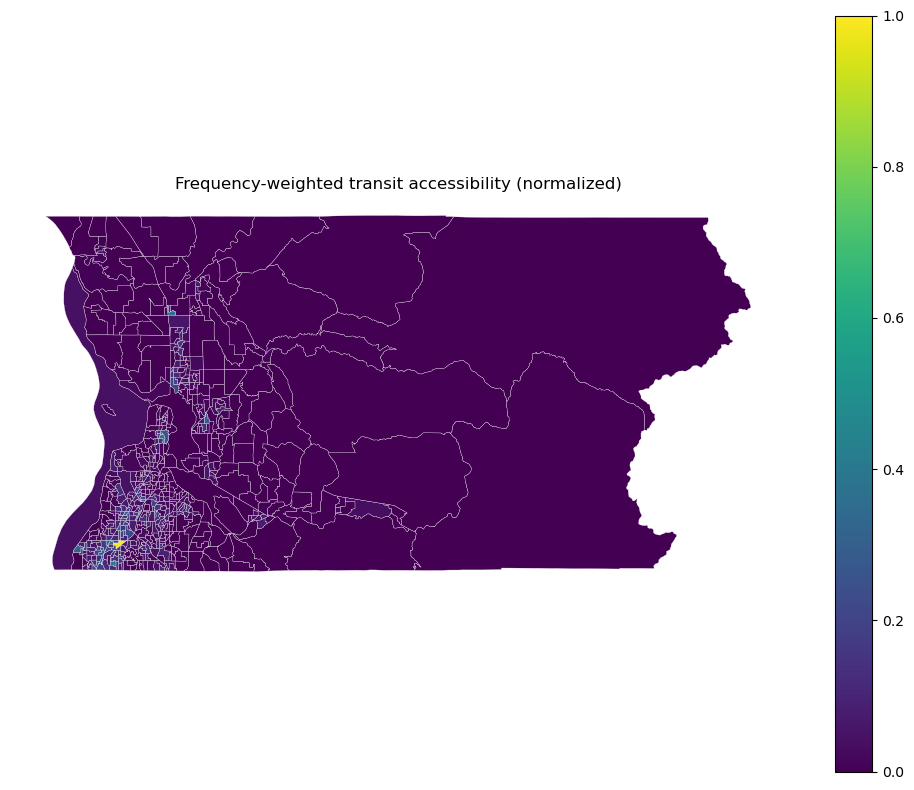

In [7]:
# QA: map accessibility surface
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 8))
acc_gdf.plot(
    column='norm_accessibility',
    cmap='viridis',
    legend=True,
    linewidth=0.2,
    edgecolor='white',
    ax=ax
)
ax.set_title('Frequency-weighted transit accessibility (normalized)')
ax.set_axis_off()
plt.tight_layout()
plt.show()

In [6]:
# QA: sensitivity to beta parameter
from transit_gaps.accessibility import compute_accessibility
import pandas as pd

betas = [2.0, 4.0, 6.0, 8.0]
results = {}
for b in betas:
    tmp = compute_accessibility(
        network=network, stops_gdf=stop_freq, vuln_gdf=vuln_gdf,
        beta=b, out_path=f'/tmp/acc_beta{b}.parquet'
    )
    results[f'beta={b}'] = tmp['norm_accessibility']

pd.DataFrame(results).corr()

/home/simonhans/coding/snotrac/src/transit_gaps/accessibility.py:93: RuntimeWarning: invalid value encountered in cast
  poi_idx = distances_m[id_col].values.astype(int)
/home/simonhans/coding/snotrac/src/transit_gaps/accessibility.py:111: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  centroids = vuln_proj.geometry.centroid


Saved accessibility scores → /tmp/acc_beta2.0.parquet  (575 block groups)


/home/simonhans/coding/snotrac/src/transit_gaps/accessibility.py:93: RuntimeWarning: invalid value encountered in cast
  poi_idx = distances_m[id_col].values.astype(int)
/home/simonhans/coding/snotrac/src/transit_gaps/accessibility.py:111: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  centroids = vuln_proj.geometry.centroid


Saved accessibility scores → /tmp/acc_beta4.0.parquet  (575 block groups)


/home/simonhans/coding/snotrac/src/transit_gaps/accessibility.py:93: RuntimeWarning: invalid value encountered in cast
  poi_idx = distances_m[id_col].values.astype(int)
/home/simonhans/coding/snotrac/src/transit_gaps/accessibility.py:111: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  centroids = vuln_proj.geometry.centroid


Saved accessibility scores → /tmp/acc_beta6.0.parquet  (575 block groups)
Saved accessibility scores → /tmp/acc_beta8.0.parquet  (575 block groups)


/home/simonhans/coding/snotrac/src/transit_gaps/accessibility.py:93: RuntimeWarning: invalid value encountered in cast
  poi_idx = distances_m[id_col].values.astype(int)
/home/simonhans/coding/snotrac/src/transit_gaps/accessibility.py:111: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  centroids = vuln_proj.geometry.centroid


,beta=2.0,beta=4.0,beta=6.0,beta=8.0
beta=2.0,1.000000,0.929505,0.803314,0.682723
beta=4.0,0.929505,1.000000,0.960555,0.884631
beta=6.0,0.803314,0.960555,1.000000,0.978351
beta=8.0,0.682723,0.884631,0.978351,1.000000
